# 02b — Limiter scores and ranking

Each candidate limiter gets a **severity** (0 = no concern, 1 = clearly limiting),
built from linear ramps between documented reference points
(`goalsplit_research.limiters.PARAMS`), and a **confidence** from how much data backs
it. Severity × the event's **relevance** weight (`RELEVANCE`) gives the ranking score,
computed separately for 10K, half marathon, marathon and backyard ultra.

The athlete's pre-registered belief, recorded before this ran: **load management**.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt

from goalsplit_research import data, datasets, limiters as L

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.spines.top": False, "axes.spines.right": False})

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
daily = data.daily_frame(ds)
races = datasets.road_races(ds, acts)
ctx = L.Context.at(ds["today"], acts, daily, races)
riegel = L.riegel_exponent(races)
print(f"Assessed as of {ds['today']}: last 12 weeks for intensity and base, last 12 months for durability and load")

Assessed as of 2026-10-26: last 12 weeks for intensity and base, last 12 months for durability and load


## The evidence behind each limiter

In [2]:
result = L.assess(ctx, riegel=riegel)
for lim in result["Marathon"][:4] + [b for ev in L.EVENTS for b in result[ev] if b.key == "base"]:
    sev = "—" if lim.severity is None else f"{lim.severity:.2f}"
    tag = "" if lim.key != "base" else f" [{next(ev for ev in L.EVENTS if lim in result[ev])}]"
    print(f"{lim.label}{tag}: severity {sev}, confidence {lim.confidence}")
    for k, v in lim.evidence.items():
        print(f"    {k}: {round(v, 3) if isinstance(v, float) else v}")

Aerobic durability: severity 0.20, confidence 1.0
    median_drift_pct_90min_plus: 3.365
    long_runs: 23
    riegel_b: 1.084
Speed vs endurance balance: severity 0.00, confidence 1.0
    riegel_b: 1.084
Intensity distribution: severity 0.00, confidence 1.0
    low_share_z1_z2: 0.843
    moderate_share_z3: 0.096
    high_share_z4_z5: 0.061
Load management and consistency: severity 0.82, confidence 1.0
    breaks_14d_plus: 2
    acwr_spike_day_share: 0.107
    weekly_load_cv: 0.882
Aerobic base and long runs [10K]: severity 0.09, confidence 1.0
    weekly_hours_last_12wk: 5.389
    best_12wk_weekly_hours: 5.916
    volume_ratio: 0.911
    weeks_with_60min_run: 10/12
Aerobic base and long runs [Half marathon]: severity 0.26, confidence 1.0
    weekly_hours_last_12wk: 5.389
    best_12wk_weekly_hours: 5.916
    volume_ratio: 0.911
    weeks_with_90min_run: 6/12
Aerobic base and long runs [Marathon]: severity 0.37, confidence 1.0
    weekly_hours_last_12wk: 5.389
    best_12wk_weekly_hour

## Ranking by event


10K
                        limiter  severity  relevance  score  confidence
Load management and consistency      0.82        0.8   0.66         1.0
             Aerobic durability      0.20        0.3   0.06         1.0
     Aerobic base and long runs      0.09        0.6   0.05         1.0
         Intensity distribution      0.00        0.7   0.00         1.0
     Speed vs endurance balance      0.00        1.0   0.00         1.0

Half marathon
                        limiter  severity  relevance  score  confidence
Load management and consistency      0.82        0.8   0.66         1.0
     Aerobic base and long runs      0.26        0.8   0.20         1.0
             Aerobic durability      0.20        0.6   0.12         1.0
         Intensity distribution      0.00        0.7   0.00         1.0
     Speed vs endurance balance      0.00        0.7   0.00         1.0

Marathon
                        limiter  severity  relevance  score  confidence
Load management and consistency   

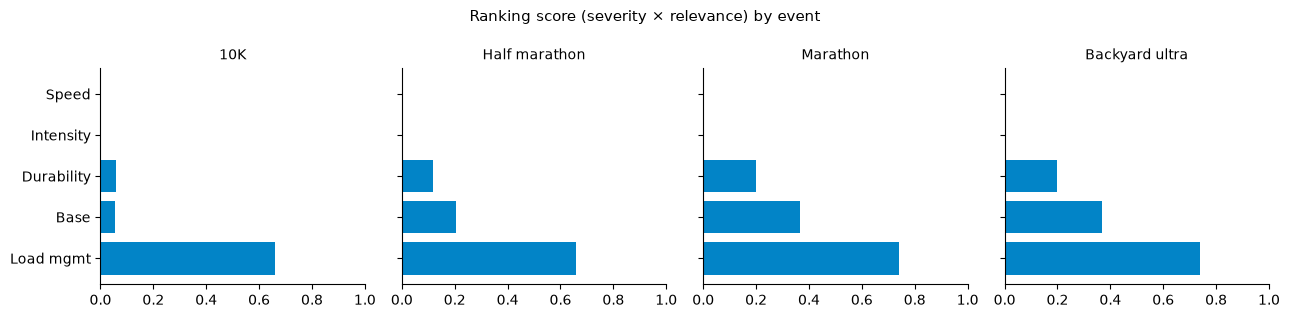

In [3]:
rankings = {ev: L.rank(result[ev], ev) for ev in L.EVENTS}
for ev, table in rankings.items():
    print(f"\n{ev}")
    print(table[["limiter", "severity", "relevance", "score", "confidence"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
keys = ["load", "base", "durability", "intensity", "speed"]
labels = {"load": "Load mgmt", "base": "Base", "durability": "Durability", "intensity": "Intensity", "speed": "Speed"}
for ax, ev in zip(axes, L.EVENTS):
    t = rankings[ev].set_index("key").reindex(keys)
    ax.barh([labels[k] for k in keys], t["score"].fillna(0), color="#0284c7")
    ax.set_title(ev, fontsize=10); ax.set_xlim(0, 1); ax.invert_yaxis()
axes[0].set_ylabel("")
fig.suptitle("Ranking score (severity × relevance) by event", fontsize=11)
plt.tight_layout(); plt.show()

## Robustness: are race weeks driving the load verdict?

A race is a deliberate load spike — an ultra especially (Backyard Cervia alone was
about 1,000 TRIMP). Re-scoring load management without race days, the week after
each race, or weeks containing a race tests whether "load management" is real or a
by-product of racing.

In [4]:
no_races = L.assess(ctx, riegel=riegel, exclude_races=True)
both = []
for label, res in [("all days", result), ("race weeks excluded", no_races)]:
    load = next(l for l in res["Marathon"] if l.key == "load")
    both.append({"measured on": label, "severity": round(load.severity, 2), **{k: round(v, 3) if isinstance(v, float) else v for k, v in load.evidence.items()}})
print(pd.DataFrame(both).to_string(index=False))
print()
for ev in L.EVENTS:
    t = L.rank(no_races[ev], ev)
    print(f"{ev:<15} top limiter without race weeks: {t.iloc[0]['limiter']} ({t.iloc[0]['score']:.2f}), "
          f"next {t.iloc[1]['limiter']} ({t.iloc[1]['score']:.2f})")

        measured on  severity  breaks_14d_plus  acwr_spike_day_share  weekly_load_cv
           all days      0.82                2                 0.107           0.882
race weeks excluded      0.65                2                 0.059           0.822

10K             top limiter without race weeks: Load management and consistency (0.52), next Aerobic durability (0.06)
Half marathon   top limiter without race weeks: Load management and consistency (0.52), next Aerobic base and long runs (0.20)
Marathon        top limiter without race weeks: Load management and consistency (0.59), next Aerobic base and long runs (0.37)
Backyard ultra  top limiter without race weeks: Load management and consistency (0.59), next Aerobic base and long runs (0.37)


## Conclusions

**Load management ranks first for every event:** 0.66 for 10K and half, 0.74 for
marathon and ultra. Severity is 0.82, driven by:
- two 14+ day breaks in the last year
- an EWMA ACWR above 1.5 on 10.7% of days
- very uneven weekly load (coefficient of variation 0.88)

**Second place depends on distance.** For the half, marathon and ultra it's
**aerobic base and long runs**: only 4 of the last 12 weeks had a 150+ minute run,
though recent volume is 91% of the athlete's best 12-week block. For the 10K, every
other limiter scores near zero.

**Not limiting right now:**
- **Intensity distribution:** the last 12 weeks were 84% low-intensity (a backyard-ultra
  block).
- **Speed vs endurance:** the Riegel exponent of 1.084 is above typical, so the
  athlete isn't short of speed *relative to* endurance. 02a showed the speed ceiling
  is untested rather than measured.
- **Durability on training runs:** median drift is only 3.4% across 23 long runs.

**Robust to racing.** Excluding race days, the week after each race and weeks
containing a race lowers load-management severity to 0.65: spike days halve to 5.9%,
but weekly unevenness (CV 0.82) and the breaks remain. It still ranks first for every
event, so the verdict isn't an artefact of deliberate race-week spikes.